<a href="https://colab.research.google.com/github/adrianacruzrivera-max/proyecto6-connectatel/blob/main/S7_Version-Estudiante-Project-ConnectaTel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# cargar archivos

plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')


In [4]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [5]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [6]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [7]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)


plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [8]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 260.0+ bytes


In [9]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [10]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [11]:
# cantidad de nulos para users
print(users.isna().sum())
print()
print(users.isna().mean().round(4))

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

user_id       0.0000
first_name    0.0000
last_name     0.0000
age           0.0000
city          0.1172
reg_date      0.0000
plan          0.0000
churn_date    0.8835
dtype: float64


In [12]:
# cantidad de nulos para usage
print(usage.isna().sum())
print()
print(usage.isna().mean().round(4))

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

id          0.0000
user_id     0.0000
type        0.0000
date        0.0012
duration    0.5519
length      0.4474
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
Si una columna tiene más del 80–90% de nulos, normalmente se ignora o elimina.
Si tiene entre 5% y 30%, generalmente se investiga para imputar o dejar como nulos.
Si es menor al 5%, suele ser un caso simple de imputación o dejar como nulos.
 ---
**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

Valores nulos
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

---

✍️ **Mi diagnóstico**

**Valores nulos**

users.city: 469 nulos (11.7%) + 96 con "?" (2.4%) = 565 (14.1%), entre 5% y 30% → dejar como nulos. La ausencia no se relaciona con plan, edad, churn, año de registro ni uso (chi-cuadrado y Mann-Whitney, p > 0.13), por lo que parece MCAR. Imputar la moda inflaría Bogotá de 23.5% a ~37%; al ser categórica no hay un valor central neutro.

users.churn_date: 3,534 nulos (88.4%), más del 80–90% → ignorar en este análisis (no imputar ni borrar filas): un nulo significa cliente activo, no un dato perdido.

usage.date: 50 nulos (0.13%), menos del 5% → dejar como nulos: no afecta los conteos por usuario.

usage.duration: 22,076 nulos (55.2%) y usage.length: 17,896 nulos (44.7%) → dejar como nulos: son nulos estructurales (duration solo aplica a llamadas y length solo a mensajes; se confirma en 3.2).

El resto de columnas no tiene valores faltantes.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [13]:
# explorar columnas numéricas de users
# aislar el sentinel: ¿cuántas edades son negativas y qué valores distintos hay?
print("Edades negativas:", (users['age'] < 0).sum(), "| valores:", users.loc[users['age'] < 0, 'age'].unique())
print("Proporción:", round((users['age'] == -999).mean() * 100, 2), "%")
# ¿el sentinel se concentra en algún plan?
print((users.groupby('plan')['age'].apply(lambda s: (s == -999).mean() * 100)).round(2))

users[['user_id', 'age']].describe()

Edades negativas: 55 | valores: [-999]
Proporción: 1.38 %
plan
Basico     1.58
Premium    1.00
Name: age, dtype: float64


,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


La columna user_id va de 10,000 a 13,999 y es consecutiva y sin duplicados (4,000 clientes únicos): es un identificador consistente.

La columna age tiene un mínimo de -999, un sentinel evidente: (users['age'] < 0).sum() da 55 casos (1.4%) y -999 es el único valor negativo. Por eso la media (33.74) y la desviación estándar (123.2) están distorsionadas; sin los sentinels la edad va de 18 a 79 años.
No es un NaN "de fábrica" sino un código de "dato no registrado". Su proporción es parecida entre planes (1.6% Básico vs 1.0% Premium), así que no parece depender de otras variables (probablemente MCAR); no se puede probar del todo, y podría ser MNAR si, por ejemplo, el cliente prefirió no dar su edad. Acción: tratarlo como nulo y reemplazarlo por la mediana (Paso 3.1).

In [14]:
# explorar columnas numéricas de usage
usage[['id', 'user_id', 'duration', 'length']].describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


Las columnas id y user_id: id es único (1 a 40,000) y user_id va de 10,000 a 13,999; todos los user_id de usage existen en users, así que no hay registros huérfanos (un usuario de users no tiene ningún uso registrado).

Las columnas duration y length: duration (minutos) va de 0 a 120 con mediana de 3.5; el valor 120 aparece exactamente 30 veces (16 mensajes de texto, que no deberían tener duración, y 14 llamadas) mientras que el percentil 99.9 de las llamadas es ~33 min: parece un valor tope artificial (sentinel). length (caracteres) va de 0 a 1,490 con mediana de 50; el valor 1,490 aparece exactamente 30 veces (18 textos y 12 llamadas, donde length debería ser nulo), no hay ningún mensaje entre 125 y 1,490 caracteres y un SMS suele limitarse a 160 caracteres: también es un sentinel, no un mensaje real.

In [15]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(users[col].value_counts(dropna=False))
    print()


city
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: count, dtype: int64

plan
Basico     2595
Premium    1405
Name: count, dtype: int64



La columna city tiene 6 ciudades válidas (Bogotá, CDMX, Medellín, GDL, Cali, MTY), pero además el sentinel "?" en 96 registros (2.4%) y 469 nulos reales: en total 565 registros (14.1%) sin ciudad conocida.

La columna plan solo tiene "Basico" (2,595; 64.9%) y "Premium" (1,405; 35.1%), coincidentes con plans.csv; no hay variantes de escritura.

In [16]:
# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)

,count
type,
text,22092
call,17908


- La columna type solo tiene "text" (22,092) y "call" (17,908); sin variantes ni errores de escritura.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?

users.age = -999 (55 filas, 1.4%) → reemplazar por la mediana de las edades válidas (48), que no se ve afectada por extremos.

users.city = "?" (96 filas, 2.4%) → reemplazar por nulo (pd.NA). Los 469 NaN de city reciben el mismo tratamiento final; ninguno de los dos muestra asociación con otras variables (ver 2.1).

usage.duration = 120 (30 filas: 16 textos, que no tienen duración, y 14 llamadas) y usage.length = 1490 (30 filas: 18 textos y 12 llamadas): se repiten con el valor exacto y están muy lejos del resto de la distribución (p99.9 de llamadas ≈ 33 min; el mayor mensaje normal tiene 125 caracteres) → sentinels. Acción: marcarlos como nulos (NaN) en el paso 3.3, sin imputar (la comprobación de que imputar con la mediana no cambiaría los outliers está en 3.3).

**2.3 Revisión y estandarización de fechas**

**🎯 Objetivo:**

Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**

Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.
Revisa cuántas veces aparece cada año.
Identifica fechas imposibles (ej. años futuros o negativos).
Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [17]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [18]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

,count
reg_date,
2022,1314
2023,1316
2024,1330
2026,40


- En reg_date, hay registros en 2022 (1,314), 2023 (1,316) y 2024 (1,330), pero también 40 registros con año 2026 (todos el 2026-05-10): una fecha futura imposible, porque los datos llegan hasta 2024.

- No aparecen años muy antiguos ni nulos.

In [19]:
# Convertir a fecha la columna `date` de usage
nulos_antes = usage['date'].isna().sum()
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')
print(nulos_antes, usage['date'].isna().sum())   # 50 50

50 50


In [20]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts(dropna=False).sort_index()

,count
date,
2024.0,39950
NaN,50


En date, todos los registros válidos son de 2024 (39,950) y hay 50 nulos que ya venían vacíos en el archivo (la conversión con errors='coerce' no creó ninguno nuevo). No hay años imposibles.

Basaremos el análisis en estas fechas.

In [21]:
# Fechas imposibles: posteriores a 2024 o anteriores a 2000
fuera_users = users[(users['reg_date'].dt.year > 2024) | (users['reg_date'].dt.year < 2000)]
fuera_usage = usage[(usage['date'].dt.year > 2024) | (usage['date'].dt.year < 2000)]
print(len(fuera_users), len(fuera_usage))   # 40 0
fuera_users['reg_date'].dt.date.value_counts()   # todas 2026-05-10


40 0


,count
reg_date,
2026-05-10,40


- Aparecen 40 usuarios en `reg_date` (1.0%) y ninguno en `usage`.
  
- Los 40 tienen exactamente la misma fecha, 2026-05-10: error de captura sistemático, no fechas al azar.

  
- No hay fechas anteriores a 2000 ni años negativos.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?


**✍️ Mi diagnóstico**

**Fechas fuera de rango**

**¿Aparecen años imposibles?**

- Sí: 40 usuarios (1.0%) tienen `reg_date` en 2026, una fecha futura porque los datos llegan hasta 2024. Todos comparten la misma fecha (2026-05-10), lo que apunta a un error de captura sistemático.

-  En `usage` no hay años imposibles.

**¿Qué harías con ellas?**

- Marcarlas como nulas (`NaT`) en vez de eliminar a los usuarios, ya que el resto de sus datos (edad, plan, uso) es válido: esos 40 usuarios tienen 374 registros de uso.
  
- Las 50 fechas nulas de `usage` se mantienen porque el registro de uso sigue siendo útil.

**🧩Paso 3:** Limpieza básica de datos

**3.1 Corregir sentinels y fechas imposibles**

**🎯 Objetivo:**

Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**

En age, reemplaza el sentinel -999 con la mediana.
En city, reemplaza el sentinel "?" por valores nulos (pd.NA).
Marca como nulas (pd.NA) las fechas fuera de rango.

In [22]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()  # mediana calculada solo con las edades válidas
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

,age
count,4000.000000
mean,48.136000
std,17.689919
min,18.000000
25%,33.000000
50%,48.000000
75%,63.000000
max,79.000000


In [23]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print("Quedan '?':", (users['city'] == '?').sum())
print("Nulos en city:", users['city'].isna().sum())
users['city'].value_counts(dropna=False)

Quedan '?': 0
Nulos en city: 565


,count
city,
Bogotá,808
CDMX,730
Medellín,616
NaN,469
GDL,450
Cali,424
MTY,407
<NA>,96


In [24]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'] > '2024-12-31', 'reg_date'] = pd.NaT  # los datos llegan hasta 2024

# Verificar cambios
print("Nulos en reg_date:", users['reg_date'].isna().sum())
print("Rango:", users['reg_date'].min(), "->", users['reg_date'].max())
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

Nulos en reg_date: 40
Rango: 2022-01-01 00:00:00 -> 2024-12-31 00:00:00


,count
reg_date,
2022.0,1314
2023.0,1316
2024.0,1330
NaN,40


**3.2 Corregir sentinels y fechas imposibles**

**🎯 Objetivo:**

Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**

Verifica si los nulos en duration y length son MAR(Missing At Random) revisando si dependen de la columna type.
Si confirmas que son MAR, déjalos como nulos y justifica la decisión.

In [25]:
# Verificación MAR en usage (Missing At Random) para duration
# Proporción de nulos de duration según el tipo de registro
usage.assign(duration_nulo=usage['duration'].isna()).groupby('type')['duration_nulo'].agg(['sum', 'mean'])

,sum,mean
type,,
call,0,0.000000
text,22076,0.999276


In [26]:
# Verificación MAR en usage (Missing At Random) para length
# Proporción de nulos de length según el tipo de registro
usage.assign(length_nulo=usage['length'].isna()).groupby('type')['length_nulo'].agg(['sum', 'mean'])

,sum,mean
type,,
call,17896,0.99933
text,0,0.00000


Haz doble clic aquíy escribe que tu diagnostico de nulos en duration y length

**✍️ Mi diagnóstico**

**Nulos en duration y length**

duration es nulo en el 99.93% de los textos y en 0% de las llamadas; length es nulo en el 99.93% de las llamadas y en 0% de los textos. La ausencia depende por completo de type, así que son nulos MAR (estructurales): la variable simplemente no aplica a ese tipo de evento.
Decisión: dejarlos como nulos. Imputarlos crearía datos falsos (por ejemplo, minutos para un mensaje). Las pocas excepciones (16 textos con duration y 12 llamadas con length) son inconsistencias mínimas (0.04% y 0.03%) y corresponden a los sentinels 120 y 1,490 que se marcan como nulos en el paso 3.3.

**3.3 (Complemento) Marcar los sentinels de duration (120) y length (1,490)**

Sección adicional a la plantilla, derivada del diagnóstico de 2.2.

**🎯 Objetivo:** convertir en nulos los valores tope repetidos que no son mediciones reales, para que no distorsionen los minutos por usuario ni los outliers.

In [27]:
# Marcar los sentinels como nulos (se hace DESPUÉS de la verificación MAR de 3.2)
print("duration == 120:", (usage['duration'] == 120).sum(), "| length == 1490:", (usage['length'] == 1490).sum())

usage['duration'] = usage['duration'].replace(120, np.nan)
usage['length'] = usage['length'].replace(1490, np.nan)

# Verificar cambios
print("Quedan duration == 120:", (usage['duration'] == 120).sum(), "| length == 1490:", (usage['length'] == 1490).sum())
print("Máximo duration en llamadas:", usage.loc[usage['type'] == 'call', 'duration'].max())
print("Máximo length en textos:", usage.loc[usage['type'] == 'text', 'length'].max())
print("Textos con duration:", usage.loc[usage['type'] == 'text', 'duration'].notna().sum(),
      "| Llamadas con length:", usage.loc[usage['type'] == 'call', 'length'].notna().sum())

duration == 120: 30 | length == 1490: 30
Quedan duration == 120: 0 | length == 1490: 0
Máximo duration en llamadas: 46.98
Máximo length en textos: 125.0
Textos con duration: 0 | Llamadas con length: 0


**Diagnóstico:** se marcaron como nulos 30 valores de duration y 30 de length, sin imputar (no conocemos el valor real).

**Nulo estructural (28 filas):** duration = 120 en textos (16) y length = 1490 en llamadas (12). La variable no aplica a ese tipo de evento, así que el NaN es el valor correcto.

**Dato faltante real (32 filas):** duration = 120 en llamadas (14) y length = 1490 en textos (18). La variable sí aplica, pero el valor no es confiable.
Efecto en el análisis: length no se usa más adelante. En duration, al sumar los minutos por usuario, las 14 llamadas con NaN cuentan como 0 minutos y subestiman a 14 usuarios (0.35% de la base); el efecto es pequeño y no cambia las conclusiones.

**Comprobación:** cant_minutos_llamada no interviene en las reglas de segmentación (grupo_uso usa solo conteos de llamadas y mensajes). Verificado aparte: imputar esas 14 llamadas con la mediana (3.5 min) da el mismo resultado que dejarlas en 0 (84 outliers en minutos y ninguno de los 14 usuarios es outlier); dejar el 120 sin tocar sí los habría convertido a los 14 en outliers (96 en total).

**Supuesto:** no se puede descartar que 120 sea un tope del sistema y que esas 14 llamadas sean reales y muy largas; con estos datos no es verificable.

**🧩Paso 4: Summary statistics de uso por usuario**

**4.1 Agrupación por comportamiento de uso**

**🎯Objetivo:** Resumir las variables clave de la tabla usage por usuario, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**

1. Construye una tabla agregada de **usage** por **user_id** que incluya:

- número total de mensajes
- número total de llamadas
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:

    cant_mensajes
- cant_llamadas
- cant_minutos_llamada

3. Combina esta tabla con **users.**

In [28]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas
# minutos solo de llamadas (los sentinels 120 ya son NaN desde el paso 3.3)
usage["call_min"] = usage["duration"].where(usage["type"] == "call", 0)


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg(
    is_text=("is_text", "sum"),
    is_call=("is_call", "sum"),
    call_min=("call_min", "sum")
).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,call_min
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [29]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "call_min": "cant_minutos_llamada"
})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [30]:
# Combinar la tabla agregada con el dataset de usuarios
# left join para conservar a los 4,000 usuarios (uno no tiene registros de uso: se llena con 0)
user_profile = users.merge(usage_agg, on="user_id", how="left")
cols_uso = ["cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]
user_profile[cols_uso] = user_profile[cols_uso].fillna(0)
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [31]:
# Resumen estadístico de las columnas numéricas
user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.136000,5.523000,4.477000,22.411225
std,17.689919,2.359738,2.145139,15.053351
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.080000
50%,48.000000,5.000000,4.000000,19.670000
75%,63.000000,7.000000,6.000000,30.992500
max,79.000000,17.000000,15.000000,105.540000


💡 **Comentario – Resumen estadístico por usuario (4.2)**

- **`age`**: va de 18 a 79 años, con mediana 48 y media 48.1 (casi iguales): distribución simétrica y sin valores raros. Coincide con la limpieza del paso 3 (ya no hay -999).
- **`cant_mensajes` y `cant_llamadas`**: mediana de 5 mensajes y 4 llamadas, con medias muy cercanas (5.5 y 4.5). Los máximos (17 y 15) están cerca del percentil 75 (7 y 6), por lo que no hay valores extremos llamativos.
- **Mínimos en 0**: hay 19 usuarios sin mensajes y 42 sin llamadas. La mayoría solo hizo una de las dos actividades (18 de los 19 sí llamaron y 41 de los 42 sí escribieron); solo 1 usuario no tiene ningún registro de uso (el que rellenamos con 0 en el merge).
- **`cant_minutos_llamada`**: mediana 19.7 y media 22.4; el máximo es **105.5**, a 5.5 desviaciones estándar de la media y muy por encima del percentil 75 (31.0). Es un **valor atípico**, pero plausible: forma una cola continua (96.9, 88.5, 87.6, 87.4…) y no un salto, y corresponde a usuarios con llamadas largas (el máximo promedia ~11.7 min por llamada frente a ~5 min en toda la base).
- **Lectura**: la cola larga a la derecha en minutos anticipa que habrá outliers superiores; se confirman con boxplots e IQR en el Paso 5 y se decide ahí si mantenerlos.

In [32]:
# Distribución porcentual del tipo de plan
(user_profile['plan'].value_counts(normalize=True) * 100).round(2)

,proportion
plan,
Basico,64.88
Premium,35.12


💡 **Comentario – Distribución de `plan`:** la base está concentrada en el plan Básico: casi 2 de cada 3 usuarios (64.88%, 2,595) frente a 35.12% en Premium (1,405). Aun así, Premium pesa más en ingresos (≈53% de la facturación mensual: 1,405 × 25 vs 2,595 × 12). Ambas categorías tienen suficientes casos para compararlas en los pasos siguientes.

**🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers**

**5.1 Visualización de Distribuciones**
    
**🎯 Objetivo:**
    
Entender visualmente cómo se comportan las variables clave tanto de uso como de clientes, observar si existen diferencias según el tipo de plan, y analizar la forma de la distribución.

**Instrucciones:**

Graficar histogramas para las siguientes columnas:

age (edad de los usuarios)
cant_mensajes
cant_llamadas
total_minutos_llamada
Después de cada gráfico, escribe un insight respecto al plan y la variable, por ejemplo:

"Dentro del plan Premium, hay mayor proporción de..."
"Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes." o "No existe algún patrón."
¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)
Hint
Para cada histograma,

Usa hue='plan' para ver cómo varían las distribuciones según el plan (Básico o Premium).
Usa palette=['skyblue','green']
Agrega título y etiquetas

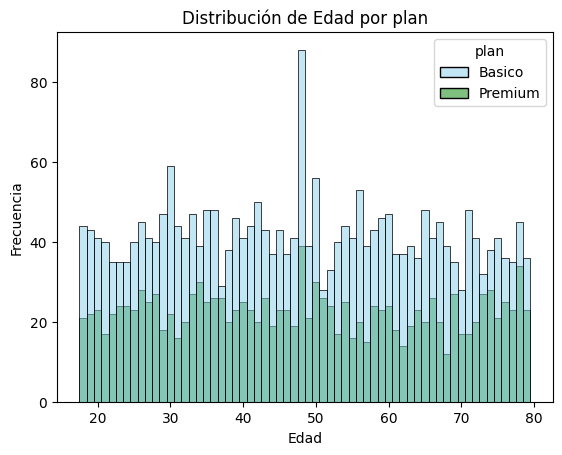

In [33]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue','green'], discrete=True)
plt.title('Distribución de Edad por plan')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()

💡Insights:

-Distribución plana y simétrica (asimetría 0.05): hay clientes de todas las edades entre 18 y 79, sin una concentración clara.
Ambos planes tienen la misma edad promedio (Básico 48.0 y Premium 48.3), por lo que no existe un patrón de edad por plan; en cada grupo de 10 años Premium ronda el 33–38%.

-El pico aislado en 48 años (127 usuarios) viene de la imputación con la mediana de los 55 registros con -999; no refleja un comportamiento real.

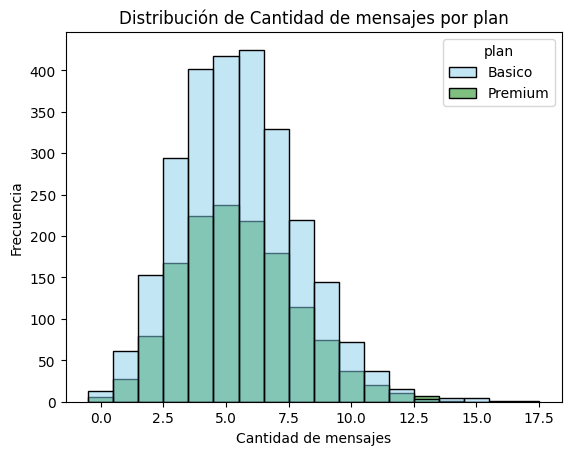

In [34]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue','green'], discrete=True)
plt.title('Distribución de Cantidad de mensajes por plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Frecuencia')
plt.show()

💡Insights:

-Distribución ligeramente sesgada a la derecha (asimetría 0.46): la mayoría envía entre 4 y 7 mensajes (61% de los usuarios; mediana 5; moda 5 con 655 usuarios), con una cola que llega hasta 17.

-Los usuarios Básico y Premium se comportan igual (promedio 5.53 vs 5.52 mensajes): no hay patrón según el plan.

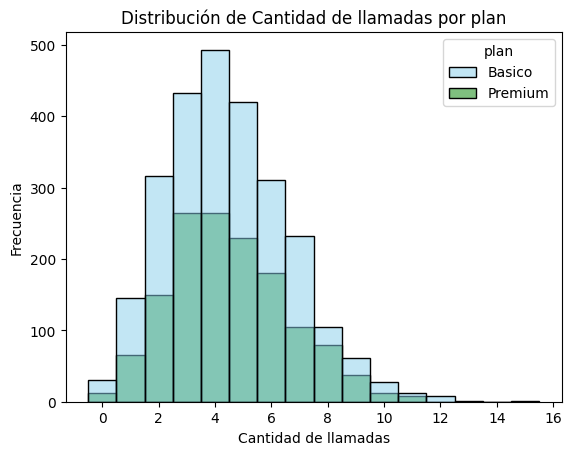

In [35]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue','green'], discrete=True)
plt.title('Distribución de Cantidad de llamadas por plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Frecuencia')
plt.show()

💡Insights:

-Distribución ligeramente sesgada a la derecha (asimetría 0.50), con mediana de 4 llamadas y máximo de 15.

-Los usuarios Básico hacen en promedio 4.45 llamadas y los Premium 4.52: diferencia insignificante, sin patrón por plan.

-La moda es 4 llamadas (757 usuarios) y nadie tiene exactamente 14 llamadas: es un hueco real de los datos, no un artefacto del bin.

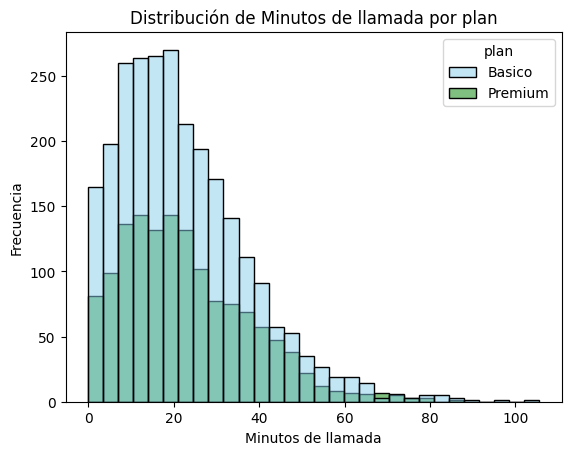

In [36]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue','green'], bins=30)
plt.title('Distribución de Minutos de llamada por plan')
plt.xlabel('Minutos de llamada')
plt.ylabel('Frecuencia')
plt.show()

💡Insights:

-Distribución fuertemente sesgada a la derecha (asimetría 1.03): casi todos hablan menos de 40 minutos y unos pocos superan los 60 (el máximo es 105.5).

-Los Premium hablan solo un poco más (22.9 vs 22.2 min en promedio; mediana 20.3 vs 19.4). Aunque pagan más del doble, su uso es casi idéntico al de los usuarios Básico.

**5.2 Identificación de Outliers**

**🎯 Objetivo:**

Detectar valores extremos en las variables clave de uso y clientes que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**

**Usa boxplots para identificar visualmente outliers en las siguientes columnas:**
-age
-cant_mensajes
-cant_llamadas
-total_minutos_llamada
-Crea un for para generar los 4 boxplots automáticamente.

**Después de crear los gráfico, responde si existen o no outliers en las variables.**

-Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el método IQR y decide qué hacer con ellos.
-Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.
Hint:

Dentro del bucle, usa plt.title(f'Boxplot: {col}') para que el título cambie acorde a la columna.

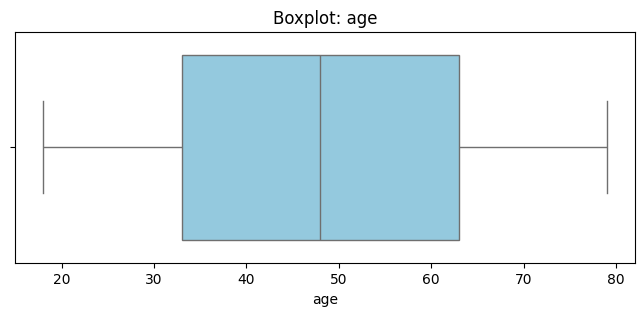

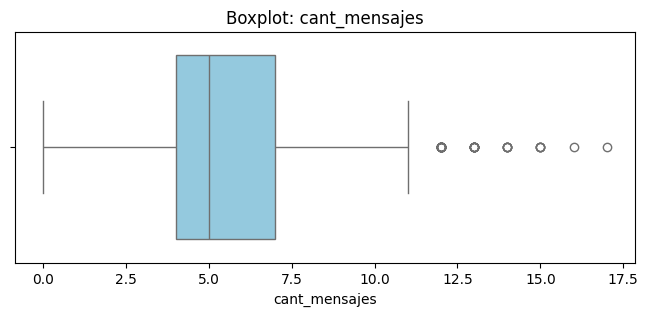

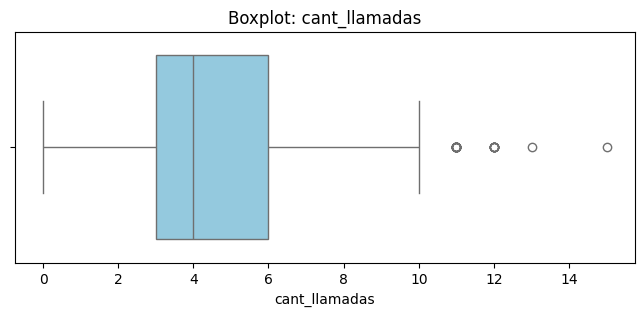

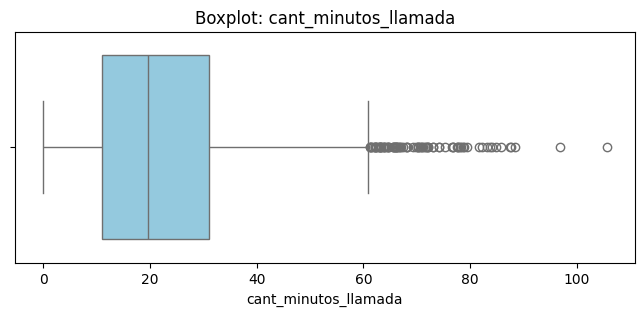

In [37]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=user_profile[col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights:

- `age`: no presenta outliers; la caja cubre 33–63 años y los bigotes llegan a 18 y 79.

-  `cant_mensajes`: presenta outliers, solo por el lado superior.

-  `cant_llamadas`: presenta outliers, solo por el lado superior.

-  `cant_minutos_llamada`: presenta outliers, solo por el lado superior, y son los más dispersos.


In [38]:
# Límite superior (IQR) para las variables con outliers
columnas_outliers = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_outliers:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1
    limite_superior = q3 + 1.5 * iqr
    n_outliers = (user_profile[col] > limite_superior).sum()
    print(f"{col}: Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}, límite superior={limite_superior:.2f}, "
          f"outliers={n_outliers} ({n_outliers / len(user_profile) * 100:.2f}%), máximo={user_profile[col].max():.2f}")

cant_mensajes: Q1=4.00, Q3=7.00, IQR=3.00, límite superior=11.50, outliers=46 (1.15%), máximo=17.00
cant_llamadas: Q1=3.00, Q3=6.00, IQR=3.00, límite superior=10.50, outliers=30 (0.75%), máximo=15.00
cant_minutos_llamada: Q1=11.08, Q3=30.99, IQR=19.91, límite superior=60.86, outliers=84 (2.10%), máximo=105.54


In [39]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_outliers].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,22.411225
std,2.359738,2.145139,15.053351
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.080000
50%,5.000000,4.000000,19.670000
75%,7.000000,6.000000,30.992500
max,17.000000,15.000000,105.540000


💡Insights:

- `cant_mensajes`: mantener o no outliers, ¿por qué? → **Mantener.** Límite superior 11.5; 46 usuarios (1.15%), máximo 17. Es un valor plausible, no un error: son usuarios muy activos.
  
- `cant_llamadas`: mantener o no outliers, ¿por qué? → **Mantener.** Límite superior 10.5; 30 usuarios (0.75%), máximo 15. Es un uso alto pero real y consistente con el resto del comportamiento.

- `cant_minutos_llamada`: mantener o no outliers, ¿por qué? → **Mantener.** Límite superior 60.86; 84 usuarios (2.1%), máximo 105.5 min. Es una cola natural del consumo (el máximo es ~3.4 veces el percentil 75, pero posible) y corresponde a los clientes que más usan el servicio; eliminarlos ocultaría justamente a los más valiosos. Para resumir esta variable conviene usar la mediana.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [40]:
# Crear columna grupo_uso
user_profile['grupo_uso'] = np.where(
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5), 'Bajo uso',
    np.where((user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10), 'Uso medio', 'Alto uso')
)

user_profile['grupo_uso'].value_counts()


,count
grupo_uso,
Uso medio,2943
Bajo uso,779
Alto uso,278


In [41]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [42]:
# Crear columna grupo_edad
user_profile['grupo_edad'] = np.where(
    user_profile['age'] < 30, 'Joven',
    np.where(user_profile['age'] < 60, 'Adulto', 'Adulto Mayor')
)

user_profile['grupo_edad'].value_counts()


,count
grupo_edad,
Adulto,2018
Adulto Mayor,1222
Joven,760


In [43]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

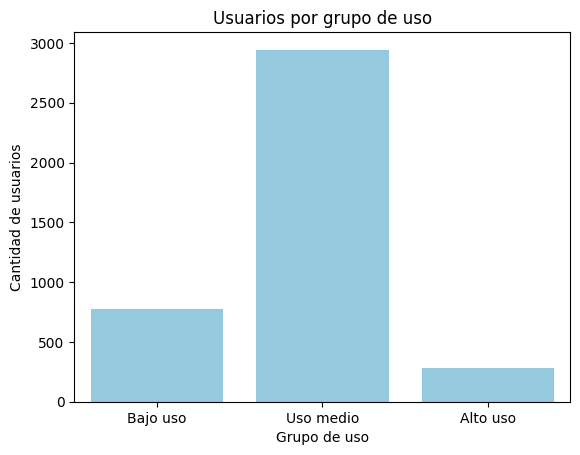

In [44]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'], color='skyblue')
plt.title('Usuarios por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

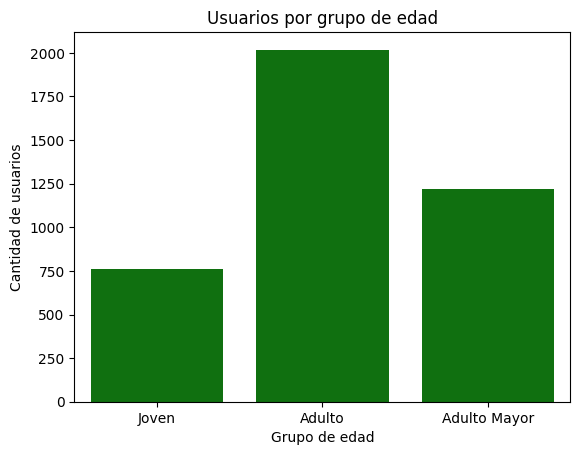

In [45]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'], color='green')
plt.title('Usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()


**6.4 (Complemento opcional) Segmentación por país**
    
**Sección adicional a la plantilla:** se puede omitir sin afectar el resto del flujo.

**🎯 Objetivo:** el enunciado del proyecto pide comparar segmentos por país. users_latam.csv no trae país, pero se puede derivar de la ciudad (ConnectaTel opera en México y Colombia): CDMX, GDL y MTY → México; Bogotá, Medellín y Cali → Colombia.

In [46]:
# Derivar el país a partir de la ciudad
pais_por_ciudad = {'CDMX': 'México', 'GDL': 'México', 'MTY': 'México',
                   'Bogotá': 'Colombia', 'Medellín': 'Colombia', 'Cali': 'Colombia'}
user_profile['pais'] = user_profile['city'].map(pais_por_ciudad)

print(user_profile['pais'].value_counts(dropna=False))
print()
# Uso promedio por país (los usuarios sin ciudad quedan fuera de la comparación)
user_profile.groupby('pais')[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].mean().round(2)

pais
Colombia    1848
México      1587
NaN          565
Name: count, dtype: int64



,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
pais,,,,
Colombia,48.36,5.54,4.50,22.65
México,47.93,5.48,4.45,22.28


grupo_uso  Alto uso  Bajo uso  Uso medio
pais                                    
Colombia        7.0      18.5       74.5
México          6.2      20.3       73.5


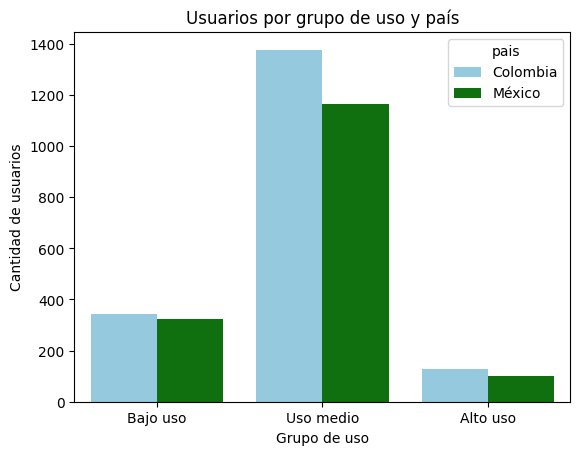

In [47]:

# Distribución de grupos de uso por país (% dentro de cada país)
print((pd.crosstab(user_profile['pais'], user_profile['grupo_uso'], normalize='index') * 100).round(1))

sns.countplot(data=user_profile.dropna(subset=['pais']), x='grupo_uso', hue='pais',
              order=['Bajo uso', 'Uso medio', 'Alto uso'], palette=['skyblue', 'green'])
plt.title('Usuarios por grupo de uso y país')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡Insights:

- Colombia concentra 1,848 clientes (46.2%) y México 1,587 (39.7%); 565 (14.1%) no tienen ciudad conocida y por eso quedan sin país (`pais` se derivó de `city`).
  
- El uso es prácticamente idéntico entre países (≈5.5 mensajes, ≈4.5 llamadas, ≈22.5 minutos) y la mezcla de grupos de uso también (Alto uso 7.0% Colombia vs 6.2% México). En el gráfico las barras de Colombia son más altas porque tiene más clientes, no porque use más.

- No hay evidencia de que el país sea un factor diferenciador del uso; con estos datos no se justifican planes distintos por país.


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**


## Análisis ejecutivo

### ⚠️ Problemas detectados en los datos

- `users.age`: 55 filas (1.4%) con el sentinel -999, que distorsionaba la media (33.7 vs 48.1 real). Se reemplazó por la mediana (48).
- `users.city`: 96 filas (2.4%) con "?" y 469 nulos (11.7%); en total 565 clientes (14.1%) sin ciudad. Se dejaron como nulos.
- `users.reg_date`: 40 filas (1.0%) con fecha en 2026, imposible para datos hasta 2024. Se marcaron como nulas.
- `usage.date`: 50 filas (0.13%) sin fecha.
- `usage.duration` / `length`: 55.2% y 44.7% de nulos, pero estructurales según el tipo (llamada o texto), por lo que se dejaron. Además, `duration` = 120 (30 filas) y `length` = 1,490 (30 filas) son sentinels repetidos, marcados como nulos sin imputar: 28 son nulos estructurales (variable que no aplica al tipo de evento) y 32 son datos faltantes reales; las 14 llamadas con 120 cuentan como 0 minutos (efecto pequeño: 14 usuarios).
- `users.churn_date`: 88.4% de nulos, que corresponde a clientes activos; viene en notación científica poco usable como fecha.

### 🔍 Segmentos por edad

- La base es principalmente Adulta (50.5%, 2,018 clientes), con 30.6% de Adultos Mayores (1,222) y solo 19.0% de Jóvenes (760).
- El comportamiento de uso es prácticamente igual en los tres grupos: ~5.5 mensajes, ~4.5 llamadas y ~22.5 minutos. La edad por sí sola no explica diferencias de consumo ni de plan (en cada grupo ~65% está en Básico y ~35% en Premium). Tampoco hay diferencias por país (México vs Colombia, ver 6.4).

### 📊 Segmentos por nivel de uso

- **Uso medio** (73.6%, 2,943 clientes) es el corazón de la base: ~5.8 mensajes y ~4.8 llamadas.
- **Bajo uso** (19.5%, 779 clientes): ~3 mensajes y ~3 llamadas. Su tasa de baja (11.4%) es igual a la de Uso medio (11.5%), así que su bajo consumo no implica mayor abandono; es una oportunidad de activación.
- **Alto uso** (7.0%, 278 clientes): 9.6 mensajes, ~6 llamadas y ~30 minutos; casi el doble de mensajes que el promedio. Su tasa de baja (14.0%) es algo mayor que la del resto (11.5%), por lo que merecen atención de retención.
- **Valor:** los clientes Premium son el 35% de la base pero generan ~53% del ingreso mensual recurrente (1,405 × USD 25 = USD 35,125 frente a 2,595 × USD 12 = USD 31,140, según `plans.csv`). Por tamaño, el bloque Adulto + Uso medio (1,500 clientes, 37.5%) es el más grande. Alto uso pesa poco en ingresos (6.9%), pero es el segmento con mayor riesgo de baja.
- **Outliers (solo hacia arriba):** 46 usuarios (1.15%) con más de 11.5 mensajes, 30 (0.75%) con más de 10.5 llamadas y 84 (2.1%) con más de 60.9 minutos (máximo 105.5). No existen outliers hacia abajo: los límites inferiores son negativos (-0.5 mensajes, -1.5 llamadas, -18.8 minutos) y el mínimo real es 0; `age` tampoco tiene outliers. Se mantuvieron por ser plausibles; implican una pequeña "élite de consumo" con demanda de más minutos/mensajes.

➡️ Esto sugiere que el uso de los clientes es muy homogéneo y bajo (la mayoría usa mucho menos que lo incluido en sus planes: 100 minutos y 100 mensajes al mes en Básico) y que ni la edad ni el plan contratado predicen el consumo: los clientes Premium se comportan igual que los Básico.

### 💡 Recomendaciones

1. **Rediseñar la propuesta del plan Premium:** su uso real es casi igual al de Básico y hay riesgo de que los clientes perciban que pagan más por lo mismo y cambien de plan o se vayan. Reforzar sus beneficios (más GB, servicios adicionales) o ajustar su precio.
2. **Crear un plan de entrada más económico** para el segmento de Bajo uso (19.5%), con menos minutos y mensajes incluidos.
3. **Programa de fidelización para Alto uso:** ofertas personalizadas o un plan con más minutos/mensajes, aprovechando que su tasa de baja (14.0%) supera a la del resto (~11.5%).
4. **Campañas de activación para Bajo uso** y retención para Uso medio, el grupo más grande.
5. **No segmentar la oferta solo por edad:** no hay diferencias de consumo. La edad sirve para canales de comunicación y atención (por ejemplo, soporte simple para Adultos Mayores), no para el diseño del plan.
6. **Mejorar la calidad de datos en el origen:** validar edad, ciudad y fechas al capturarlas, y guardar `churn_date` como fecha estándar.

### ❓ Respuestas a las preguntas del negocio

- **¿Qué segmentos usan más o menos?** Alto uso (7.0%) y Bajo uso (19.5%) son los extremos; el resto (73.6%) es uso medio. Ni la edad, ni el plan, ni el país separan a los usuarios por consumo.
- **¿Qué segmentos parecen más valiosos y por qué?** Los más valiosos son los **clientes Premium**, por generar ~53% del ingreso mensual recurrente con solo el 35% de la base, y el bloque **Adulto + Uso medio** (1,500 clientes, 37.5%), por ser el más grande. **Alto uso** (7.0%) pesa poco en ingresos (6.9%), pero es el que más conviene retener por su mayor tasa de baja (14.0% vs 11.5%).
- **¿Qué usuarios son atípicos (fraude o errores)?** 84 usuarios con minutos muy altos (>60.9), 46 con muchos mensajes (>11.5) y 30 con muchas llamadas (>10.5), todos hacia arriba; además hay errores de registro claros: 30 registros con `duration` = 120 y 30 con `length` = 1,490 (valores tope repetidos, incluso en el tipo de evento equivocado), que se marcaron como nulos. Conviene auditar a los usuarios extremos antes de descartar fraude.
- **¿Cómo varía el uso según edad y plan?** Prácticamente no varía: ~5.5 mensajes, ~4.5 llamadas y ~22.5 minutos en todos los grupos de edad, planes y países.
- **¿Qué patrones ayudan a diseñar mejores planes?** Consumo bajo y homogéneo frente a lo incluido en los planes, Premium sin uso diferenciado y un grupo pequeño de alto consumo: ver recomendaciones.

**Limitaciones:** `usage.csv` no incluye consumo de datos (GB), y las diferencias de baja entre segmentos son pequeñas (11.4% a 14.0%), por lo que se presentan como indicio, no como conclusión estadística.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: https://github.com/Adriananacruzrivera-max/proyecto6-connectatel